<a href="https://colab.research.google.com/github/yuniecorn-dev/esaa_assignment2/blob/main/ESAA_OB_WEEK7_study_1012.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#4. 딥러닝 시작

##4.1 인공 신경망의 한계와 딥러닝 출현

###퍼셉트론
  - 다수의 신호(흐름이 있는)를 입력으로 받아 하나의 신호를 출력
  - 이 신호를 입력으로 받아 '흐른다/안 흐른다(1또는 0)'는 정보를 앞으로 전달
  
  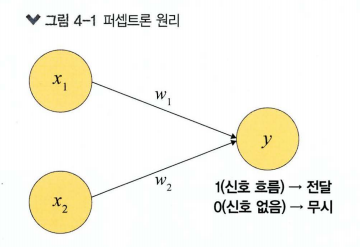

####AND 게이트
- 모든 입력이 '1'일 때 작동함.
- 입력 중 어떤 하나라도 '0'을 갖는다면 작동을 멈춤.


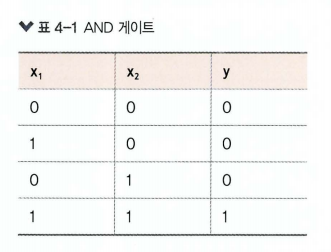
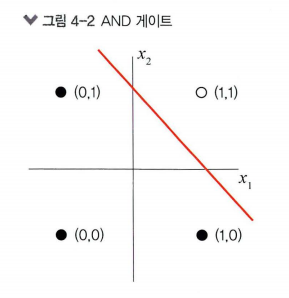

####OR 게이트
- 둘 중 하나만 '1'이거나 둘 다 '1'일 때 작동.
- 입력 모두가 '0'을 갖는 경우를 제외한 나머지가 모두 '1' 값을 가짐.

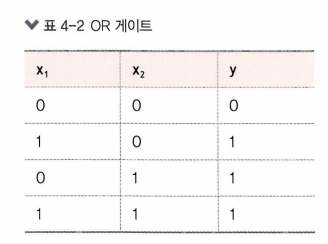
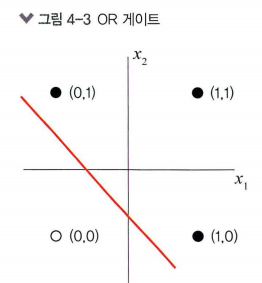

####XOR 게이트
- 배타적 논리합
- 입력 두 개 중 한 개만 '1'일 때 작동하는 논리 연산

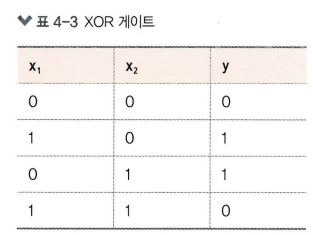

- 데이터가 비선형적으로 분리되기 때문에 제대로 된 분류가 어려움.

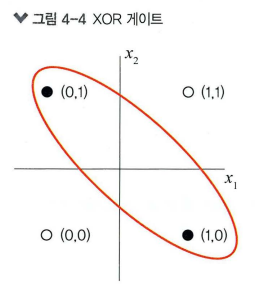

####다층 퍼셉트론
- 입력층과 출력층 사이에 하나 이상의 중간층(은닉층)을 두기
- 비선형적으로 분리되는 데이터에 대해서도 학습이 가능
- 심층 신경망 (=딥러닝)
  - 입력층과 출력층 사이에 은닉층이 여러 개 있는 신경망

##4.2 딥러닝 구조

###4.2.1 딥러닝 용어

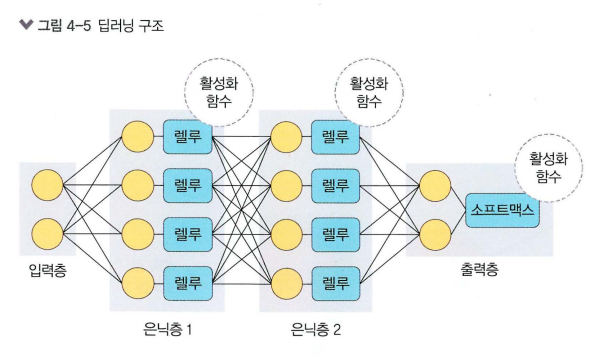

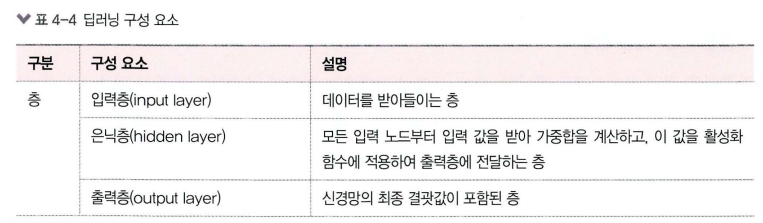

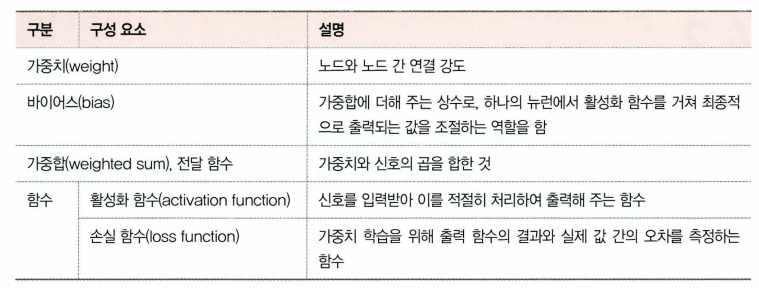

####가중치
- 입력 값이 연산 결과에 미치는 영향력을 조절하는 요소
- 예시
  - w1 값이 0 혹은 0과 가까운 0.0001이면
  - x1이 아무리 큰 값이라도 x1 x w1 값은 0이거나 0에 가까운 값
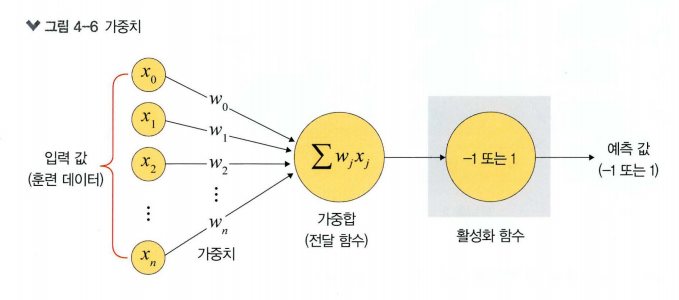

####가중합 또는 전달 함수
- 각 노드에서 들어오는 신호에 가중치를 곱해서 다음 노드로 전달
- 이 값들을 모두 더한 합계를 가중합이라고 함.
- 노드의 가중합이 계산되면 이 가중합을 활성화 함수로 보냄.

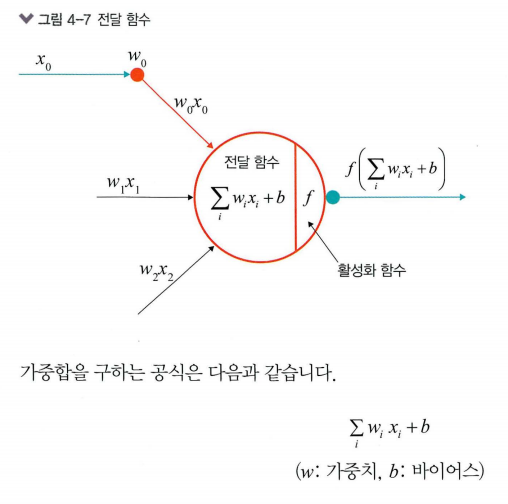

####활성화 함수
- 전달 함수에서 전달받은 값을 출력할 때 일정 기준에 따라 출력 값을 변화시키는 비선형 함수
- 시그모이드, 하이퍼볼릭 탄젠트, 렐루 함수
___
1. 시그모이드 함수
- 선형 함수의 결과를 0~1 사이에서 비선형 형태로 변형해 줌.
- 로지스틱 회귀와 같은 분류 문제를 확률적으로 표현하는 데 사용
- 기울기 소멸 문제가 발생해 딥러닝 모델에서 잘 사용 X
- 수식

  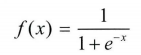
  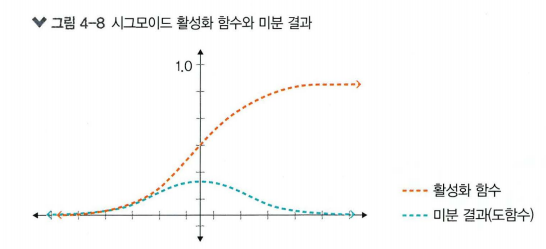

2. 하이퍼볼릭 탄젠트 함수
- 선형 함수의 결과를 -1~1 사이에서 비선형 형태로 변형
- 결과값의 평균이 0이 아닌 양수로 편향된 문제 해결

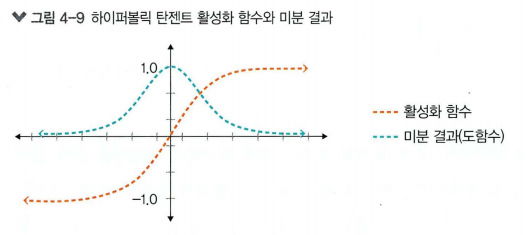

3. 렐루 함수
- 입력이 음수일 때는 0을 출력, 양수일 때는 x를 출력
- 경사 하강법에 영향을 주지 않아 학습 속도가 빠름.
- 기울기 소멸 문제 X
- 은닉층에 사용.
- 음수 값을 입력받으면 항상 0을 출력하기 때문에 학습 능력이 감소.

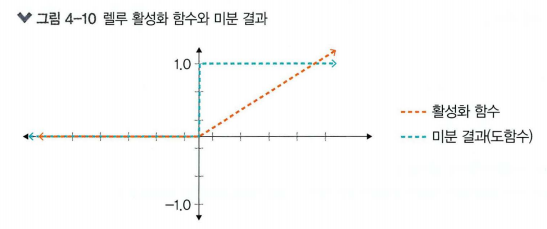

4. 리키 렐루 함수
- 입력 값이 음수이면 0이 아닌 0.0001처럼 매우 작은 수를 반환
- 입력 값이 수렴하는 구간이 제거됨.

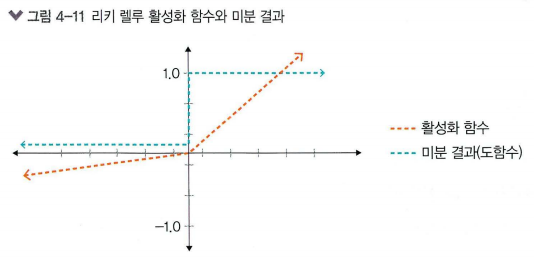

5. 소프트맥스 함수
- 입력 값을 0~1사이에 출력되도록 정규화하여 출력 값들의 총합이 항상 1이 되도록 함.
- 수식

  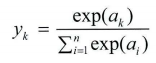

In [1]:
# 렐루 함수와 소프트맥스 함수
import torch

class Net(torch.nn.Module):
  def __init__(self, n_feature, n_hidden, n_output):
    super(Net, self).__init__()
    self.hidden = torch.nn.Linear(n_feature, n_hidden)
    self.relu = torch.nn.ReLu(inplace=True)
    self.out =torch.nn.Linear(n_hidden, n_output)
    self.softmax = torch.nn.Softmax(dim=n_output)
  def forward(self, x):
    x = self.hidden(x)
    x = self.relu(x)
    x = self.out(x)
    x = self.softmax(x)
    return x

####손실함수

- 경사 하강법
  - 학습률과 손실함수의 순간 기울기를 이용해 가중치를 업데이트 하는 방법
  - 미분의 기울기를 이용해 오차를 비교하고 최소화하는 방향으로 이동시키는 방법
  - 오차를 구하는 방법 = 손실 함수
- 손실 함수
  - 학습을 통해 얻은 데이터의 추정치가 실제 데이터와 얼마나 차이가 나는지 평가하는 지표
  - 클수록 많이 틀렸다. 0에 가까울수록 완벽하게 추정할 수 있다.
  - MSE, CEE
- 평균 제곱 오차 (MSE)
  - 실제 값과 예측 값의 차이
  - 이 값이 작을수록 예측력이 좋음.
  - 수식
  
    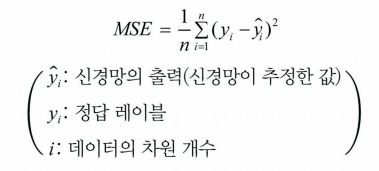

In [1]:
# MSE
import torch
loss_fn = torch.nn.MSELoss(reduction='sum')
y_pred = model(x)
loss = loss_fn(y_pred, y)

- 크로스 엔트로피 오차 (CEE)
  - 분류 문제에서 원-핫 인코딩했을 때 사용할 수 있는 오차 계산법
  - 두 개의 확률 분포 차이를 이용하기 때문에 시그모이드의 영향을 덜 받음.
  - 학습 속도가 빠름.
  - 수식

  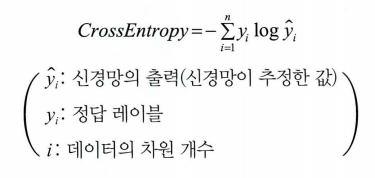

In [ ]:
# CEE
loss = nn.CrossEntropyLoss()
input = torch.randn(5, 6, requires_grad=True)
target = torch.empty(3, dtype=torch.long).random_(5)
output =loss(input, target)
output.backward()

###4.2.2 딥러닝 학습
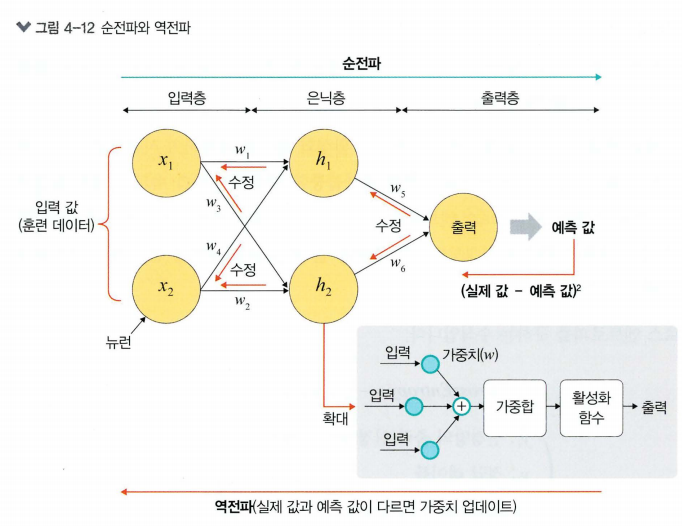

1. 순전파(feedforward)
- 네트워크에 훈련 데이터가 들어올 때 발생
- 데이터를 기반으로 예측 값을 계산하기 위해 전체 신경망을 교차해 지나감.
- 네트워크를 통해 입력 데이터를 전달하며, 데이터가 모든 층을 통과하고 모든 뉴런이 계산을 완료하면 그 예측값은 최종 층(출력층)에 도달
2. 역전파(backpropagation)
- 예측값과 실제값의 차이(손실, 오차)를 추정
- 손실함수 비용이 0에 가깝도록 하기 위해 가중치 조정
- 손실이 계산되면 역으로 전파(출력층 -> 은닉층 -> 입력층)됨.

###4.2.3 딥러닝의 문제점과 해결 방안

- 활성화 함수가 적용된 은닉층의 개수가 많을수록 데이터 분류가 잘되고 있음
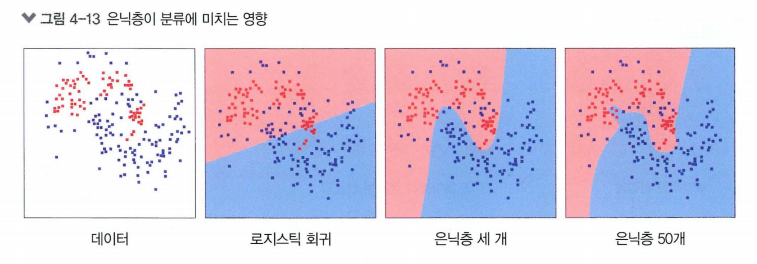

####과적합 문제
- 훈련 데이터에 대해 과하게 학습하여 실제 데이터에 대한 오차가 증가하는 현상
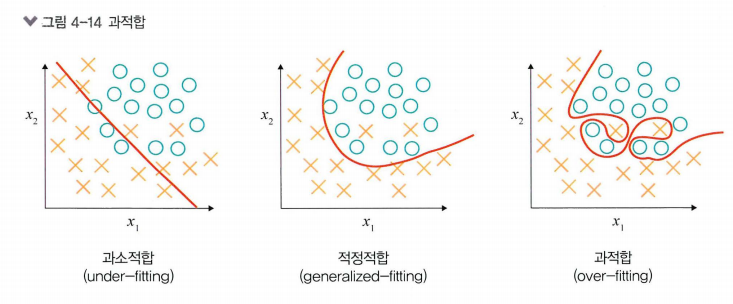

해결방법: 드롭아웃
- 학습 과정 중 임의로 일부 노드들을 학습에서 제외시킴

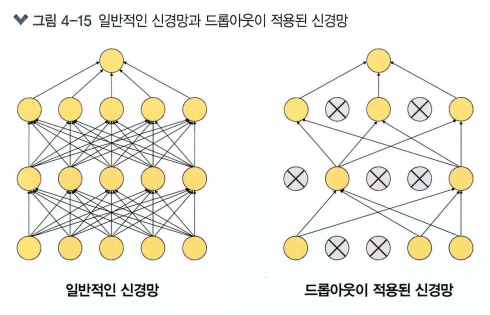

In [3]:
# 드롭아웃
class DropoutModel(torch.nn.Module):
  def __init__(self):
    super(DropoutModel, self).__init__()
    self.layer1 = torch.nn.Linear(784, 1200)
    self.dropout1 = torch.nn.Dropout(0.5)
    self.layer2 = torch.nn.Linear(1200, 1200)
    self.dropout2 = torch.nn.Dropout(0.5)
    self.layer3 = torch.nn.Linear(1200, 10)

  def forward(self, x):
    x = F.relu(self.layer1(x))
    x = self.dropout1(x)
    x = F.relu(self.layer2(x))
    x = self.dropout2(x)
    return self.layer3(x)

####기울기 소멸 문제 발생
- 출력층에서 은닉층으로 전달되는 오차가 크게 줄어 학습이 되지 않는 현상

해결방법: 렐루 활성화 함수(시그모이드 or 하이퍼볼릭 탄젠트 대신)

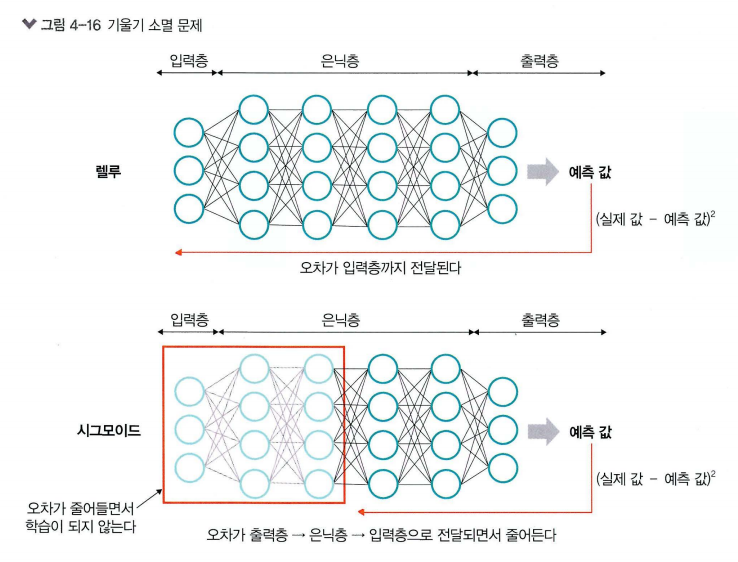

####성능 저하
해결 방법: 확률적 경사 하강법, 미니 배치 경사 하강법

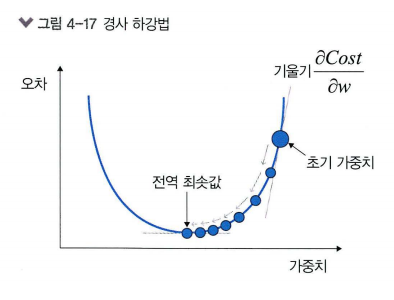

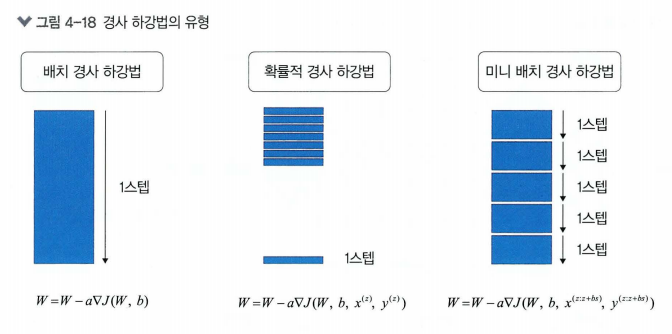

- 배치 경사 하강법
  - 전체 데이터셋에 대한 오류를 구한 후 기울기를 한 번만 계산하여 모델의 파라미터를 업데이트 하는 방법
  - 전체 훈련 데이터셋에 대해 가중치를 편미분하는 방법
  - 수식

    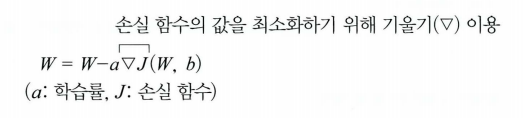
  - 학습이 오래 걸림

- 확률적 경사 하강법
  - 임의로 선택한 데이터에 대해 기울기를 계산하는 방법
  - 빠른 계산 가능

  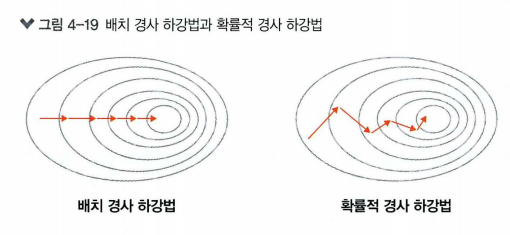



- 미니 배치 경사 하강법
  - 전체 데이터셋을 미니 배치 여러 개로 나누고, 미니 배치 한 개마다 기울기를 구한 후 그것의 평균 기울기를 이용해 모델을 업데이트해 학습하는 방법

  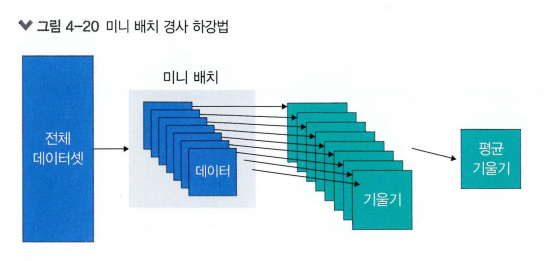
  - 안정적이면서 속도도 빠름

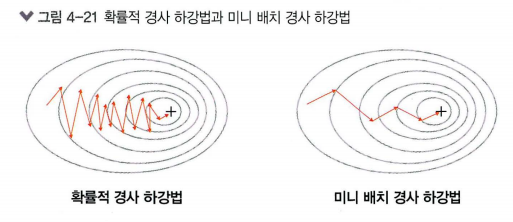


In [ ]:
class CustomDataset(Dataset):
  def __init__(self):
    self.x_data = [[1, 2, 3], [4, 5, 6], [7, 8, 9]]
    self.y_data = [[12], [18], [11]]
    def __len__(self):
      return len(self.x_data)
    def __getitem__(self, idx):
      x = torch.FloatTensor(self.x_data[idx])
      y = torch.FloatTensor(self.y_data[idx])
      return x, y

dataset = CutomDataset()
dataloader = DataLoader(
  dataset,
  batch_size=2,
  shuffle=True,
)

### 딥러닝 옵티마이저(Optimizer) 정리

> **옵티마이저(Optimizer)**: 확률적 경사 하강법(SGD)의 파라미터 변경 폭이 불안정한 문제를 해결하기 위해 학습 속도(Learning Rate)와 운동량(Momentum)을 조정하는 기법
---

#### 1. 옵티마이저 발전 계보

- **속도 개선 계열**: 확률적 경사 하강법(SGD) → 아다그라드(Adagrad) → 아다델타(Adadelta) / 알엠에스프롭(RMSprop)
- **운동량 개선 계열**: 확률적 경사 하강법(SGD) → 모멘텀(Momentum) → 네스테로프 모멘텀(NAG)
- **혼용(속도 + 운동량)**: RMSprop + Momentum → **아담(Adam)** (현재 가장 보편적이며 성능도 우수)

---

#### 2. 속도를 조정하는 방법

1) 아다그라드 (Adagrad, Adaptive Gradient)
- **개념**: 변수(가중치)의 업데이트 횟수에 따라 학습률을 적응적으로 조정합니다.
  - 많이 변화한 변수: 학습률을 작게 설정 (최적값 근처에 도달했을 것으로 가정)
  - 적게 변화한 변수: 학습률을 크게 설정 (오차를 빠르게 줄임)
- **수식**:
  $$w(i+1) = w(i) - \frac{\eta}{\sqrt{G(i) + \varepsilon}} \nabla E(w(i))$$
  $$G(i) = G(i-1) + (\nabla E(w(i)))^2$$
  *(단, $G$는 기울기 크기의 누적값)*
- **한계**: 학습이 진행될수록 $G(i)$ 값이 커져 학습률이 0에 수렴하며 학습이 멈추는 현상이 발생합니다.
- **PyTorch 구현**:
  ```python
  optimizer = torch.optim.Adagrad(model.parameters(), lr=0.01)  # 기본 lr: 1e-2

2) 아다델타 (Adadelta, Adaptive Delta)

* **개념**: Adagrad에서 $G$ 값이 계속 커져 학습이 멈추는 문제를 해결하기 위해 등장
  - 학습률 $\eta$ 대신 가중치의 변화량($\Delta$) 크기 누적값을 사용하여 하이퍼파라미터(학습률) 설정이 필요 없음.
* **수식**:

$$w(i+1) = w(i) - \frac{\sqrt{D(i-1) + \varepsilon}}{\sqrt{G(i) + \varepsilon}} \nabla E(w(i))$$


$$G(i) = \gamma G(i-1) + (1 - \gamma)(\nabla E(w(i)))^2$$


$$D(i) = \gamma D(i-1) + (1 - \gamma)(\Delta w(i))^2$$


* **PyTorch 구현**:
```python
optimizer = torch.optim.Adadelta(model.parameters(), lr=1.0)  # 기본 lr: 1.0

```



---

3) 알엠에스프롭 (RMSprop)

* **개념**: Adagrad의 $G(i)$ 값이 무한히 커지는 것을 방지하기 위해 지수 이동 평균(Exponential Moving Average)을 적용한 방법
  - 지수 감쇄 비율 $\gamma$(감마)를 도입하여 학습률이 너무 작아지는 것을 막음.
* **수식**:

$$w(i+1) = w(i) - \frac{\eta}{\sqrt{G(i) + \varepsilon}} \nabla E(w(i))$$


$$G(i) = \gamma G(i-1) + (1 - \gamma)(\nabla E(w(i)))^2$$


* **PyTorch 구현**:
```python
optimizer = torch.optim.RMSprop(model.parameters(), lr=0.01)  # 기본 lr: 1e-2
```

####3. 운동량을 조정하는 방법
1) 기본 확률적 경사 하강법 (SGD)

* **수식**:

$$w(i+1) = w(i) - \eta \nabla E(w(i))$$



---

2) 모멘텀 (Momentum)

* **개념**: 가중치를 수정하기 전에 이전 수정 방향(+/-)의 관성(운동량)을 고려하여 일정한 비율만큼 추가 이동시키는 방법
  - 지그재그 현상을 줄여주고 빠르게 수렴
* **수식**:

$$w(i+1) = w(i) - v(i)$$


$$v(i) = \gamma v(i-1) + \eta \nabla E(w(i))$$



*(단, $v$는 속도(velocity))*
* **PyTorch 구현**:
```python
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
# momentum 값은 보통 0.9에서 시작하여 0.95, 0.99로 조정하며 사용

```



---

3) 네스테로프 모멘텀 (NAG, Nesterov Accelerated Gradient)

* **개념**: 관성에 의해 멈춰야 할 시점에서도 지나치게 멀리 이동하는 모멘텀의 단점을 보완
  - 모멘텀 방향으로 먼저 절반 정도 이동한 위치에서 기울기를 다시 계산하여 제동을 걸어줌.
* **수식**:

$$w(i+1) = w(i) - v(i)$$


$$v(i) = \gamma v(i-1) + \eta \nabla E(w(i) - \gamma v(i-1))$$


* **PyTorch 구현**:
```python
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9, nesterov=True)
# nesterov 기본값은 False
```



####4. 속도와 운동량의 혼용 방법

아담 (Adam, Adaptive Moment Estimation)
- 모멘텀(Momentum)의 관성 효과와 **RMSprop**의 적응형 학습률 방식을 결합한 최적화 알고리즘
- RMSprop의 $G$ 함수와 모멘텀의 $v(i)$ 속도를 함께 적용
* **수식**:

$$w(i+1) = w(i) - \frac{\eta}{\sqrt{G(i) + \varepsilon}} v(i)$$


$$G(i) = \gamma_2 G(i-1) + (1 - \gamma_2)(\nabla E(w(i)))^2$$


$$v(i) = \gamma_1 v(i-1) + \eta \nabla E(w(i))$$


* **PyTorch 구현**:
```python
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)  # 기본 lr: 1e-3
```

###4.2.4 딥러닝을 사용할 때 이점
####특성 추출
- 데이터별로 어떤 특징을 가지고 있는지 찾아내고, 그것을 토대로 데이터를 벡터로 변환하는 작업
- 특성추출 과정을 알고리즘에 통합시켜 전문지식 필요성 적어짐.
####빅데이터의 효율적 활용
- 딥러닝 학습을 이용한 특성 추출은 데이터 사례가 많을수록 성능이 향상됨.

##4.3 딥러닝 알고리즘
- 합성곱 신경망(CNN)
- 순환 신경망(RNN)
- 제한된 볼트만 머신(RBM)
- 심층 신뢰 신경망(DBN)

###4.3.1 심층 신경망
- 입력층과 출력층 사이에 다수의 은닉층을 포함하는 인공 신경망
- 다수의 은닉층을 두어 비선형 분류 가능
- 학습을 위한 연산량이 많고 기울기 소멸 문제 발생 가능성 있음
- 해결: 드롭아웃, 렐루함수, 배치 정규화 적용해야 함.

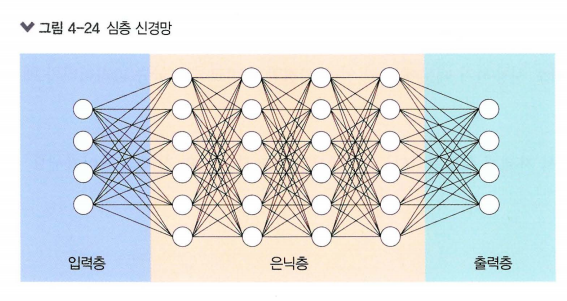

###4.3.2 합성곱 신경망
- 합성곱층과 풀링층을 포함하는 이미지 처리 성능이 좋은 인공 신경망 알고리즘
- 이미지에서 객체, 얼굴, 장면을 인식하기 위한 패턴을 찾는 데 유용

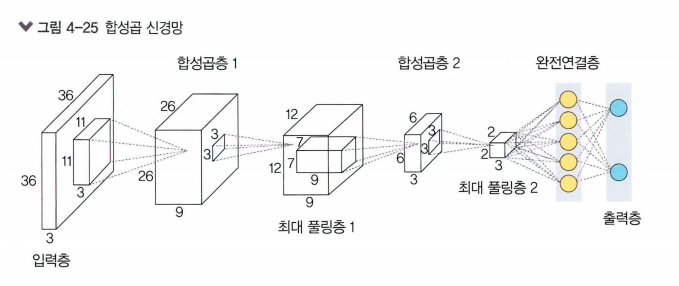
- LeNet-5, AlexNet
  - 층을 더 깊게 쌓은 신경망: VGG, GoogLeNet, ResNet
- 차별성
  - 각 층의 입출력 현상을 유지
  - 이미지의 공간 정보를 유지하면서 인접 이미지와 차이가 있는 특징을 효과적으로 인식
  - 복수 필터로 이미지의 특징을 추출하고 학습
  - 추출한 이미지의 특징을 모으고 강화하는 풀링층이 존재
  - 필터를 공유 파라미터로 사용하기 때문에 일반 인공 신경망과 비교하여 학습 파라미터가 매우 적음.

###4.3.3 순환 신경망
- 시계열 데이터(음악, 영상 등) 같은 시간 흐름에 따라 변화하는 데이터를 학습하기 위한 인공 신경망
- 순환
  - 자기 자신을 참조한다
  - 현재 결과가 이전 결과와 연관이 있다

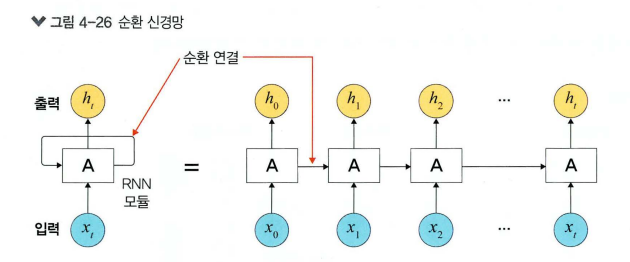

- 특징
  - 시간성을 가진 데이터가 많음
  - 시간성 정보를 이용해 데이터의 특징을 잘 다룸
  - 신간에 따라 내용이 변하므로 데이터는 동적이고, 길이가 가변적
  - 매우 긴 데이터를 처리하는 연구가 활발히 진행되고 있음
- 예시
  - 언어 모델링
  - 텍스트 생성
  - 자동 번역
  - 음성 인식
  - 이미지 캡션 생성

###4.3.4 제한된 볼츠만 머신
- 가시층과 가시층, 은닉층과 은닉층 사이에 연결이 없는 것

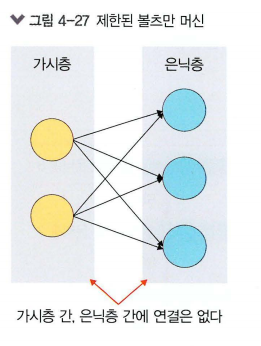

- 특징
  - 차원 감소, 분류, 선형 회귀 분석, 협업 필터링, 특성 값 학습, 주제 모델링에 사용
  - 기울기 소멸 문제를 해결하기 위한 사전 학습 용도로 사용
  - 심층 신뢰 신경망(DBN)의 요소로 사용

###4.3.5 심층 신뢰 신경망
- 입력층과 은닉층으로 구성된 제한된 볼츠만 머신을 블록처럼 여러 층으로 쌓은 형태로 연결된 신경망
- 레이블이 없는 데이터에 대한 비지도 학습이 가능
- 부분적인 이미지에서 전체를 연상하는 일반화와 추상화 과정을 구현할 때 사용하면 유용함.
- 학습 절차
  1. 가시층과 은닉층 1에 제한된 볼츠만 머신을 사전 훈련
  2. 첫 번째 층 입력 데이터와 파라미터를 고정하여 두 번째 층 제한된 볼츠만 머신을 사전 훈련
  3. 원하는 층 개수만큼 제한된 볼츠만 머신을 쌓아올려 전체 DBN 완성

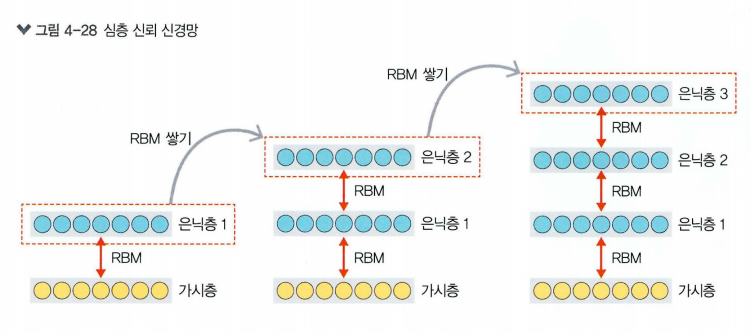